In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent
RAW_DIR = ROOT_DIR / "data" / "raw"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"

In [2]:
dim_customer = pd.read_csv(PROCESSED_DIR / "dim_customer.csv")
dim_product = pd.read_csv(PROCESSED_DIR / "dim_product.csv")
dim_seller = pd.read_csv(PROCESSED_DIR / "dim_seller.csv")
fact_order = pd.read_csv(PROCESSED_DIR / "fact_order.csv")
fact_order_item = pd.read_csv(PROCESSED_DIR / "fact_order_item.csv")

In [3]:
fact_order["order_purchase_timestamp"] = pd.to_datetime(
    fact_order["order_purchase_timestamp"]
)

fact_order["order_approved_at"] = pd.to_datetime(
    fact_order["order_approved_at"]
)

fact_order["order_delivered_carrier_date"] = pd.to_datetime(
    fact_order["order_delivered_carrier_date"]
)

fact_order["order_delivered_customer_date"] = pd.to_datetime(
    fact_order["order_delivered_customer_date"]
)

fact_order["order_estimated_delivery_date"] = pd.to_datetime(
    fact_order["order_estimated_delivery_date"]
)

In [4]:
sales = (
    fact_order
    .merge(
        fact_order_item,
        on="order_id",
        how="left"
    )
    .merge(
        dim_customer,
        on="customer_id",
        how="left"
    )
    .merge(
        dim_product,
        on="product_id",
        how="left"
    )
)

In [5]:
sales.shape

(113425, 28)

In [6]:
sales.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,estimated_delay_days,...,customer_unique_id,customer_zip_code,customer_city,customer_state,product_category_name,product_category_name_english,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,-7.107488,...,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,utilidades_domesticas,housewares,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,-5.355729,...,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,perfumaria,perfumery,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,-17.245498,...,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,automotivo,auto,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,-12.980069,...,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,pet_shop,pet_shop,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,-9.238171,...,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,papelaria,stationery,250.0,51.0,15.0,15.0


In [8]:
sales["year_month"] = (
    sales["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

In [9]:
monthly_sales = (
    sales
    .query("order_status != 'canceled'")
    .groupby("year_month")
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique"),
        items=("order_item_id", "count"),
        customers=("customer_unique_id", "nunique")
    )
    .reset_index()
)

In [10]:
monthly_sales["aov"] = (
    monthly_sales["revenue"]
    / monthly_sales["orders"]
)

In [11]:
monthly_sales.head()

,year_month,revenue,orders,items,customers,aov
0,2016-09,207.86,2,5,2,103.930000
1,2016-10,46514.99,300,349,297,155.049967
2,2016-12,10.90,1,1,1,10.900000
3,2017-01,120098.27,797,953,763,150.687917
4,2017-02,244959.35,1763,1936,1738,138.944611


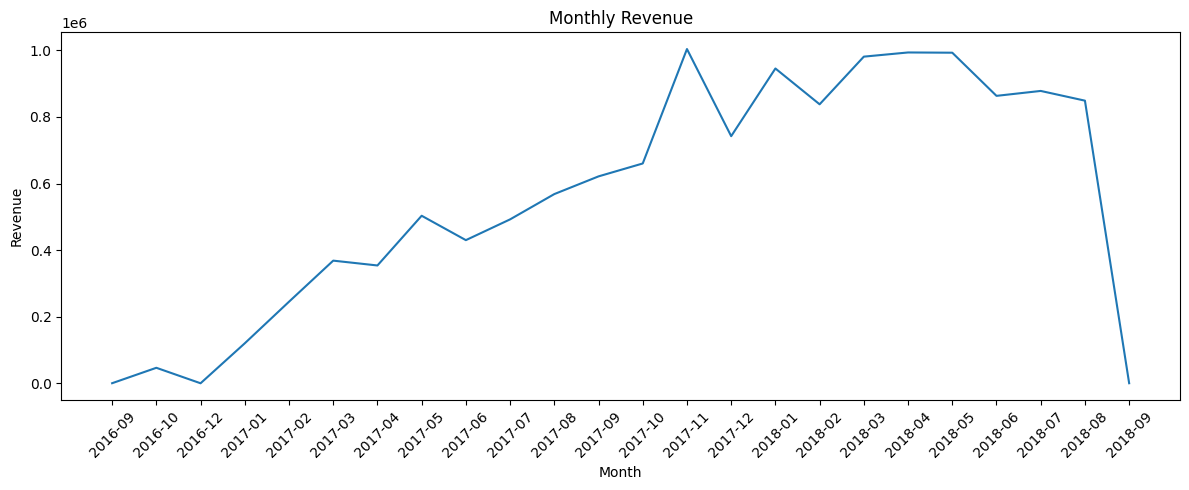

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["year_month"],
    monthly_sales["revenue"]
)

plt.xticks(rotation=45)
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

In [13]:
monthly_sales["mom_growth"] = (
    monthly_sales["revenue"]
    .pct_change()
    * 100
)

In [14]:
monthly_sales.sort_values(
    "mom_growth",
    ascending=False
).head(10)

,year_month,revenue,orders,items,customers,aov,mom_growth
3,2017-01,120098.27,797,953,763,150.687917,1.101719e+06
1,2016-10,46514.99,300,349,297,155.049967,2.227804e+04
4,2017-02,244959.35,1763,1936,1738,138.944611,1.039658e+02
13,2017-11,1003862.14,7507,8626,7396,133.723477,5.205894e+01
5,2017-03,368341.32,2649,2975,2609,139.049196,5.036834e+01
7,2017-05,503159.19,3671,4106,3599,137.063250,4.219844e+01
15,2018-01,945456.29,7235,8173,7133,130.678133,2.738843e+01
17,2018-03,981051.06,7185,8195,7093,136.541553,1.708514e+01
10,2017-08,568245.79,4304,4882,4223,132.027368,1.542971e+01
9,2017-07,492287.30,3998,4493,3920,123.133392,1.450763e+01


In [15]:
monthly_sales.sort_values(
    "mom_growth",
    ascending=True
).head(10)

,year_month,revenue,orders,items,customers,aov,mom_growth
23,2018-09,145.00,1,1,1,145.000000,-99.982918
2,2016-12,10.90,1,1,1,10.900000,-99.976567
14,2017-12,742183.79,5662,6300,5594,131.081560,-26.067160
8,2017-06,429916.61,3229,3571,3166,133.142338,-14.556542
20,2018-06,863265.53,6149,7060,6110,140.391207,-13.053672
16,2018-02,837895.43,6655,7597,6498,125.904648,-11.376608
6,2017-04,353842.98,2386,2660,2354,148.299656,-3.936116
22,2018-08,848860.10,6428,7216,6387,132.056643,-3.323770
19,2018-05,992871.75,6849,7898,6790,144.965944,-0.072588
18,2018-04,993592.98,6924,7957,6867,143.499853,1.278417


In [16]:
category_sales = (
    sales
    .query("order_status != 'canceled'")
    .groupby("product_category_name_english")
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique"),
        items=("order_item_id", "count"),
        avg_price=("price", "mean")
    )
    .reset_index()
)

In [17]:
category_sales = category_sales.rename(
    columns={
        "product_category_name_english": "category"
    }
)

In [18]:
top_categories = (
    category_sales
    .sort_values("revenue", ascending=False)
    .head(10)
)

top_categories

,category,revenue,orders,items,avg_price
43,health_beauty,1255695.13,8800,9634,130.339955
70,watches_gifts,1198185.21,5604,5970,200.701040
7,bed_bath_table,1035964.06,9399,11097,93.355327
65,sports_leisure,979740.92,7673,8590,114.055986
15,computers_accessories,904322.02,6654,7781,116.221825
39,furniture_decor,727465.05,6425,8298,87.667516
49,housewares,626825.80,5847,6915,90.647260
20,cool_stuff,620835.39,3617,3780,164.242167
5,auto,586620.73,3873,4205,139.505524
42,garden_tools,481009.94,3505,4328,111.139080


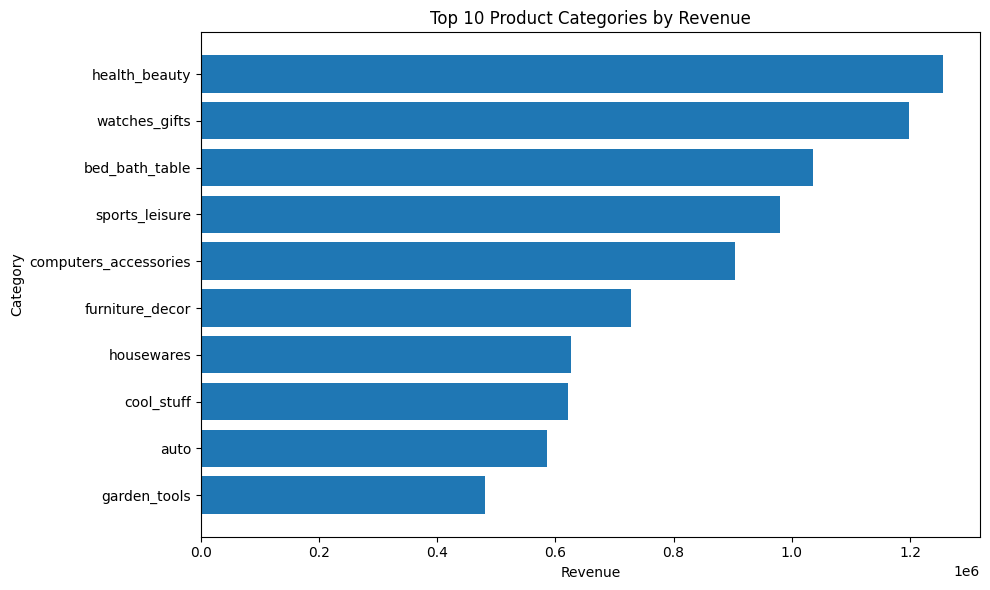

In [19]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["category"],
    top_categories["revenue"]
)

plt.gca().invert_yaxis()

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [20]:
category_sales = category_sales.sort_values(
    "revenue",
    ascending=False
).reset_index(drop=True)

In [21]:
category_sales["revenue_share"] = (
    category_sales["revenue"]
    / category_sales["revenue"].sum()
    * 100
)

In [22]:
category_sales["cumulative_share"] = (
    category_sales["revenue_share"].cumsum()
)

In [23]:
category_sales.head(20)

,category,revenue,orders,items,avg_price,revenue_share,cumulative_share
0,health_beauty,1255695.13,8800,9634,130.339955,9.432384,9.432384
1,watches_gifts,1198185.21,5604,5970,200.701040,9.000388,18.432772
2,bed_bath_table,1035964.06,9399,11097,93.355327,7.781834,26.214606
3,sports_leisure,979740.92,7673,8590,114.055986,7.359504,33.574109
4,computers_accessories,904322.02,6654,7781,116.221825,6.792981,40.367090
5,furniture_decor,727465.05,6425,8298,87.667516,5.464487,45.831577
6,housewares,626825.80,5847,6915,90.647260,4.708517,50.540094
7,cool_stuff,620835.39,3617,3780,164.242167,4.663519,55.203613
8,auto,586620.73,3873,4205,139.505524,4.406509,59.610122
9,garden_tools,481009.94,3505,4328,111.139080,3.613194,63.223316


In [24]:
category_sales[
    category_sales["cumulative_share"] <= 80
].shape[0]

16

In [25]:
customer_metrics = (
    sales
    .query("order_status != 'canceled'")
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("price", "sum"),
        items=("order_item_id", "count"),
        first_purchase=("order_purchase_timestamp", "min"),
        last_purchase=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

In [26]:
customer_metrics["customer_type"] = np.where(
    customer_metrics["orders"] > 1,
    "Repeat",
    "One-time"
)

In [27]:
customer_metrics["customer_type"].value_counts()

customer_type
One-time    92636
Repeat       2924
Name: count, dtype: int64

In [28]:
customer_metrics["customer_type"].value_counts(
    normalize=True
) * 100

customer_type
One-time    96.940142
Repeat       3.059858
Name: proportion, dtype: float64

In [29]:
customer_metrics["revenue"].describe()

count    95560.000000
mean       141.234915
std        215.728209
min          0.000000
25%         46.400000
50%         89.000000
75%        154.000000
max      13440.000000
Name: revenue, dtype: float64

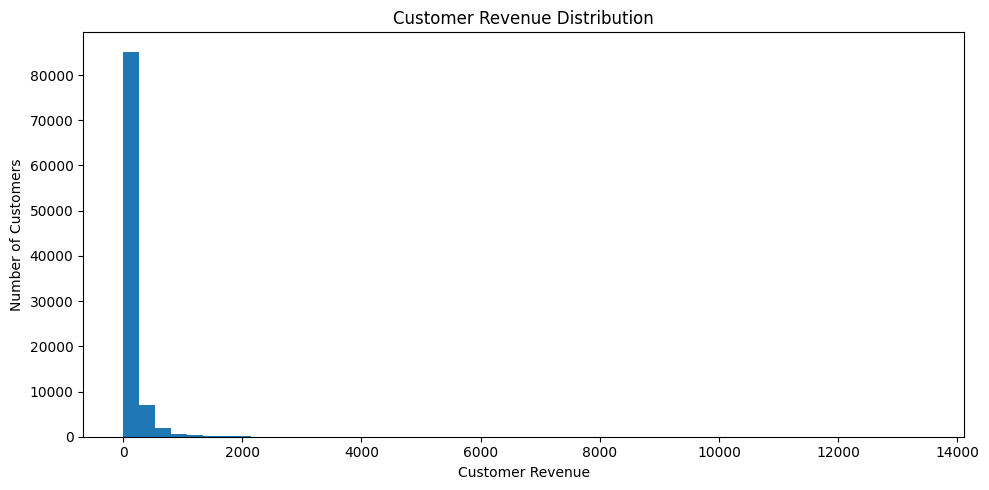

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(
    customer_metrics["revenue"],
    bins=50
)

plt.title("Customer Revenue Distribution")
plt.xlabel("Customer Revenue")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [31]:
analysis_date = (
    sales["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

analysis_date

Timestamp('2018-10-18 17:30:18')

In [32]:
rfm = (
    sales
    .query("order_status != 'canceled'")
    .groupby("customer_unique_id")
    .agg(
        recency=(
            "order_purchase_timestamp",
            lambda x: (analysis_date - x.max()).days
        ),
        frequency=("order_id", "nunique"),
        monetary=("price", "sum")
    )
    .reset_index()
)

In [33]:
rfm.head()

,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,18.90
2,0000f46a3911fa3c0805444483337064,586,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,337,1,180.00


In [34]:
rfm["r_score"] = pd.qcut(
    rfm["recency"],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
).astype(int)

In [35]:
rfm["f_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [36]:
rfm["m_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [37]:
rfm["rfm_score"] = (
    rfm["r_score"].astype(str)
    + rfm["f_score"].astype(str)
    + rfm["m_score"].astype(str)
)

In [38]:
def assign_segment(row):
    if row["r_score"] >= 4 and row["f_score"] >= 4 and row["m_score"] >= 4:
        return "Champions"
    
    elif row["r_score"] >= 4 and row["f_score"] >= 3:
        return "Loyal Customers"
    
    elif row["r_score"] >= 4:
        return "Recent Customers"
    
    elif row["r_score"] <= 2 and row["f_score"] >= 3:
        return "At Risk"
    
    else:
        return "Others"

In [39]:
rfm["segment"] = rfm.apply(
    assign_segment,
    axis=1
)

In [40]:
segment_summary = (
    rfm
    .groupby("segment")
    .agg(
        customers=("customer_unique_id", "count"),
        revenue=("monetary", "sum"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean")
    )
    .reset_index()
)

In [41]:
segment_summary

,segment,customers,revenue,avg_frequency,avg_monetary
0,At Risk,22825,3262247.54,1.048938,142.924317
1,Champions,6672,1832443.18,1.172812,274.646760
2,Loyal Customers,16266,1563630.16,1.018259,96.128745
3,Others,34486,4700187.96,1.019979,136.292639
4,Recent Customers,15311,2137899.59,1.000000,139.631611


In [42]:
delivery = fact_order[
    fact_order["order_status"] == "delivered"
].copy()

In [43]:
reviews = pd.read_csv(
    RAW_DIR / "olist_order_reviews_dataset.csv"
)

In [44]:
delivery_review = (
    delivery
    .merge(
        reviews[
            [
                "order_id",
                "review_score"
            ]
        ],
        on="order_id",
        how="left"
    )
)

In [45]:
delivery_review["delivery_bucket"] = pd.cut(
    delivery_review["delivery_days"],
    bins=[
        0,
        5,
        10,
        15,
        20,
        np.inf
    ],
    labels=[
        "<=5 days",
        "6-10 days",
        "11-15 days",
        "16-20 days",
        ">20 days"
    ]
)

In [46]:
delivery_review.groupby(
    "delivery_bucket",
    observed=True
).agg(
    orders=("order_id", "count"),
    avg_review=("review_score", "mean"),
    avg_delivery_days=("delivery_days", "mean")
)

,orders,avg_review,avg_delivery_days
delivery_bucket,,,
<=5 days,13483,4.447680,3.386331
6-10 days,33206,4.362096,7.478539
11-15 days,23753,4.265820,12.275070
16-20 days,12238,4.127950,17.193702
>20 days,14319,3.234377,29.521909


In [47]:
review_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

review_distribution

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

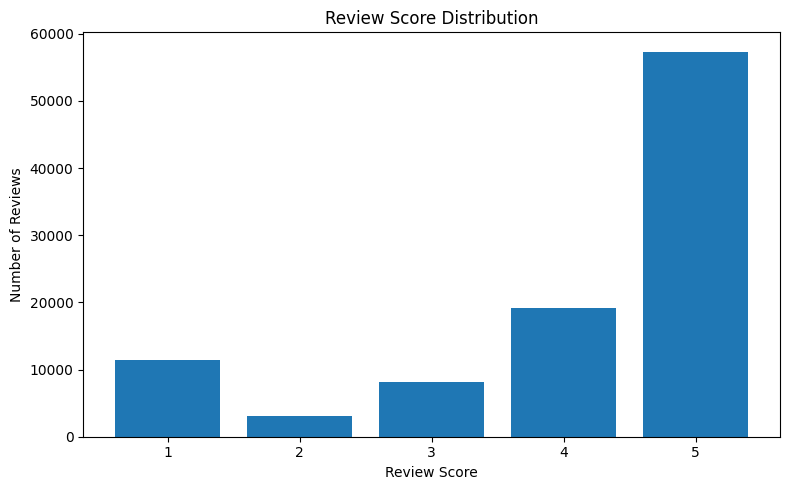

In [48]:
plt.figure(figsize=(8, 5))

plt.bar(
    review_distribution.index.astype(str),
    review_distribution.values
)

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

In [49]:
one_star = delivery_review[
    delivery_review["review_score"] == 1
]

In [50]:
one_star["delivery_days"].describe()

count    9405.000000
mean       21.311499
std        16.057158
min         0.863426
25%         9.224861
50%        16.784190
75%        30.500961
max       195.634016
Name: delivery_days, dtype: float64

In [51]:
delivery_review["delivery_days"].describe()

count    96999.000000
mean        12.564055
std          9.542396
min          0.533414
25%          6.771152
50%         10.224977
75%         15.731453
max        209.628611
Name: delivery_days, dtype: float64

In [53]:
one_star["is_late"].mean() * 100

np.float64(37.78439294067616)

In [54]:
delivery_review["is_late"].mean() * 100

np.float64(8.107662333646024)

In [55]:
state_analysis = (
    sales
    .query("order_status != 'canceled'")
    .groupby("customer_state")
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique"),
        customers=("customer_unique_id", "nunique")
    )
    .reset_index()
)

In [56]:
state_analysis["aov"] = (
    state_analysis["revenue"]
    / state_analysis["orders"]
)

In [57]:
state_analysis.sort_values(
    "revenue",
    ascending=False
).head(10)

,customer_state,revenue,orders,customers,aov
25,SP,5165166.12,41419,40022,124.705235
18,RJ,1811923.32,12766,12307,141.933520
10,MG,1573667.19,11571,11205,136.000967
22,RS,742809.68,5441,5256,136.520801
17,PR,676883.06,5023,4862,134.756731
23,SC,518578.28,3618,3519,143.332858
4,BA,507108.83,3364,3263,150.745788
6,DF,300886.45,2133,2069,141.062564
8,GO,287870.46,2007,1942,143.433214
7,ES,273532.13,2024,1956,135.144333


In [68]:
assert customer_metrics["customer_unique_id"].is_unique
assert rfm["customer_unique_id"].is_unique
assert monthly_sales["year_month"].is_unique

In [76]:
assert (
    sales["price"].isna() | (sales["price"] >= 0)
).all()

In [77]:
ANALYTICS_DIR = ROOT_DIR / "data" / "analytics"

ANALYTICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [78]:
monthly_sales.to_csv(
    ANALYTICS_DIR / "monthly_sales.csv",
    index=False
)

category_sales.to_csv(
    ANALYTICS_DIR / "category_sales.csv",
    index=False
)

customer_metrics.to_csv(
    ANALYTICS_DIR / "customer_metrics.csv",
    index=False
)

rfm.to_csv(
    ANALYTICS_DIR / "customer_rfm.csv",
    index=False
)

segment_summary.to_csv(
    ANALYTICS_DIR / "customer_segments.csv",
    index=False
)

state_analysis.to_csv(
    ANALYTICS_DIR / "state_analysis.csv",
    index=False
)

delivery_review.to_csv(
    ANALYTICS_DIR / "delivery_review_analysis.csv",
    index=False
)